<a href="https://colab.research.google.com/github/Shivaji-Vasanth/Deep-Learning/blob/main/Exp15.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Experiment 15: BPTT Flow and Gradient Analysis

1. Build a SimpleRNN and compute gradients using GradientTape

In [1]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

tf.keras.utils.set_random_seed(42)

# Simulated daily stock prices for 3 years
prices = 100 + np.cumsum(np.random.normal(0, 1, 756))
prices = (prices - prices.min()) / (prices.max() - prices.min())

def build_rnn(activation='tanh'):
    return tf.keras.Sequential([
        tf.keras.Input(shape=(None, 1)),
        tf.keras.layers.SimpleRNN(8, activation=activation),
        tf.keras.layers.Dense(1)
    ])

model = build_rnn()

x = tf.constant(prices[:10].reshape(1,10,1), dtype=tf.float32)
y = tf.constant([[prices[10]]], dtype=tf.float32)

with tf.GradientTape() as tape:
    loss = tf.reduce_mean((model(x) - y)**2)

grads = tape.gradient(loss, model.trainable_variables)

print("Loss:", float(loss))
print("Weight gradient norms:")
for g in grads:
    print(float(tf.norm(g)))


Loss: 0.6671302914619446
Weight gradient norms:
2.263286828994751
3.4951045513153076
3.596773147583008
1.5635267496109009
1.6335608959197998


2. Record gradient norm at each time step

In [2]:

def gradient_flow(length=10, activation='tanh'):
    tf.keras.utils.set_random_seed(42)
    model = build_rnn(activation)
    rnn = model.layers[0]
    dense = model.layers[1]

    x = tf.constant(prices[:length].reshape(length,1), tf.float32)
    target = tf.constant([[prices[length]]], tf.float32)

    # Initialize RNN weights
    model(tf.reshape(x, (1,length,1)))
    Wx, Wh, b = rnn.get_weights()

    h = tf.zeros((1,8))
    states = []

    with tf.GradientTape() as tape:
        for t in range(length):
            h = tf.matmul(x[t:t+1], Wx) + tf.matmul(h, Wh) + b
            h = tf.nn.tanh(h) if activation == 'tanh' else tf.nn.relu(h)
            tape.watch(h)
            states.append(h)

        prediction = dense(h)
        loss = tf.reduce_mean((prediction - target)**2)

    gradients = tape.gradient(loss, states)
    norms = [float(tf.norm(g)) for g in gradients]
    return norms

norms = gradient_flow(10)
print("Gradient norms:", np.round(norms, 6))


Gradient norms: [0.892494 0.918994 1.00908  1.104493 1.161633 1.423784 1.581017 1.645214
 1.942015 2.080487]


3. Plot gradient norm for sequence lengths 10, 50, and 100

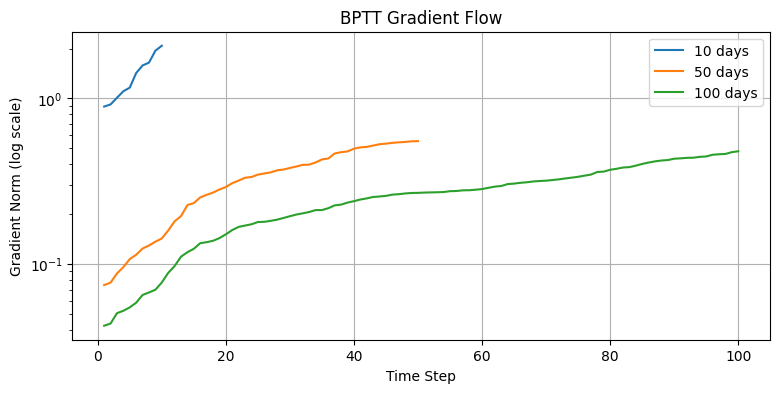

In [3]:

plt.figure(figsize=(9,4))

for length in [10,50,100]:
    norms = gradient_flow(length)
    plt.semilogy(range(1,length+1),norms,label=f'{length} days')

plt.xlabel("Time Step")
plt.ylabel("Gradient Norm (log scale)")
plt.title("BPTT Gradient Flow")
plt.legend()
plt.grid(True)
plt.show()


4. Compare tanh and ReLU activations

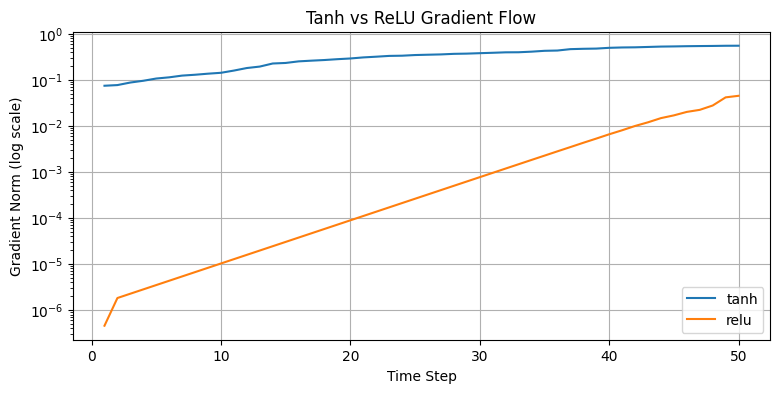

In [4]:

plt.figure(figsize=(9,4))

for activation in ['tanh','relu']:
    norms = gradient_flow(50,activation)
    plt.semilogy(range(1,51),norms,label=activation)

plt.xlabel("Time Step")
plt.ylabel("Gradient Norm (log scale)")
plt.title("Tanh vs ReLU Gradient Flow")
plt.legend()
plt.grid(True)
plt.show()


5. Explain vanishing and exploding gradients

In [5]:

for activation in ['tanh','relu']:
    norms = np.array(gradient_flow(100,activation))

    print("\nActivation:",activation)
    print("First step gradient:",round(norms[0],8))
    print("Last step gradient:",round(norms[-1],8))
    print("Maximum gradient:",round(norms.max(),8))

    if norms[0] < 1e-5:
        print("Vanishing gradient observed at early steps")
    elif norms.max() > 100:
        print("Exploding gradient observed")
    else:
        print("No severe gradient issue detected")



Activation: tanh
First step gradient: 0.04230822
Last step gradient: 0.47922993
Maximum gradient: 0.47922993
No severe gradient issue detected

Activation: relu
First step gradient: 0.0
Last step gradient: 0.17496683
Maximum gradient: 0.17496683
Vanishing gradient observed at early steps
